# Task 3: Most abundant complaint type, Jan–Feb vs Jun–Jul 2024

In [1]:
!python borough_complaints.py -i data/311_2024.csv -s 2024-01-01 -e 2024-02-29 -o data/jan_feb.csv
!python borough_complaints.py -i data/311_2024.csv -s 2024-06-01 -e 2024-07-31 -o data/jun_jul.csv

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

jan_feb = pd.read_csv('data/jan_feb.csv')
jun_jul = pd.read_csv('data/jun_jul.csv')

totals = jan_feb.groupby('complaint type')['count'].sum().sort_values(ascending=False)
totals.head(5)

complaint type
HEAT/HOT WATER          81641
Illegal Parking         79916
Noise - Residential     43602
Blocked Driveway        28608
UNSANITARY CONDITION    19208
Name: count, dtype: int64

In [3]:
top_type = totals.index[0]
top_jan_feb = jan_feb[jan_feb['complaint type'] == top_type].set_index('borough')['count']
top_jan_feb

borough
BRONX            30139
BROOKLYN         20915
MANHATTAN        17604
QUEENS           12117
STATEN ISLAND      866
Name: count, dtype: int64

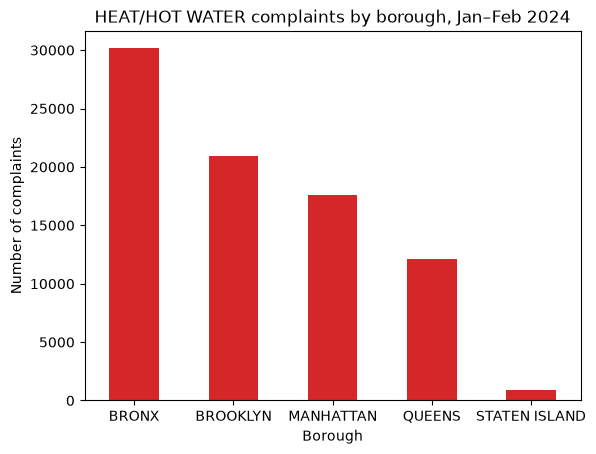

In [4]:
top_jan_feb.plot(kind='bar', color='tab:red')
plt.title(top_type + ' complaints by borough, Jan–Feb 2024')
plt.xlabel('Borough')
plt.ylabel('Number of complaints')
plt.xticks(rotation=0)
plt.show()

In [5]:
top_jun_jul = jun_jul[jun_jul['complaint type'] == top_type].set_index('borough')['count']
compare = pd.DataFrame({'Jan-Feb 2024': top_jan_feb, 'Jun-Jul 2024': top_jun_jul}).fillna(0).astype(int)
compare.loc['TOTAL'] = compare.sum()
compare

,Jan-Feb 2024,Jun-Jul 2024
borough,,
BRONX,30139,2227
BROOKLYN,20915,1929
MANHATTAN,17604,1778
QUEENS,12117,835
STATEN ISLAND,866,121
TOTAL,81641,6890


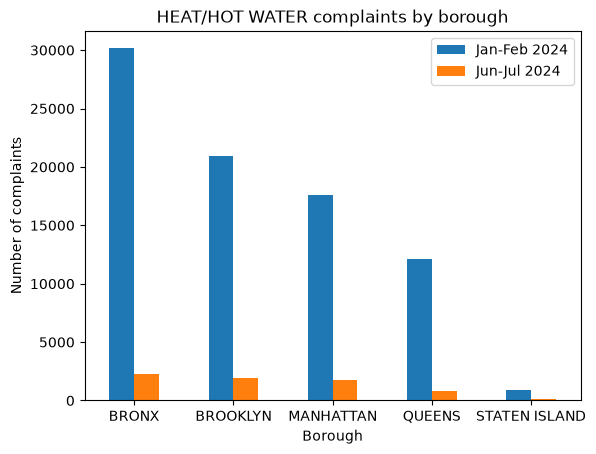

In [6]:
compare.drop('TOTAL').plot(kind='bar')
plt.title(top_type + ' complaints by borough')
plt.xlabel('Borough')
plt.ylabel('Number of complaints')
plt.xticks(rotation=0)
plt.show()

In [7]:
jun_jul_totals = jun_jul.groupby('complaint type')['count'].sum().sort_values(ascending=False)
print('Rank of', top_type, 'in Jun-Jul:', list(jun_jul_totals.index).index(top_type) + 1)
jun_jul_totals.head(5)

Rank of HEAT/HOT WATER in Jun-Jul: 25


complaint type
Illegal Parking            86240
Noise - Residential        58197
Noise - Street/Sidewalk    47320
Blocked Driveway           27193
Water System               21653
Name: count, dtype: int64